In [1]:
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
from torch.utils.data import TensorDataset, DataLoader
import pickle

### 1. Введение

**1. Типы задач рекуррентных нейронных сетей:**
- Обработка текста: классификация тональности, определение языка, генерация текста
- Временные ряды: прогноз цен, погоды, показаний датчиков
- Аудио и речь: распознавание и синтез речи
- Рекомендательные системы: моделирование сессий пользователя

**2. Формулировки задач:**
- **1 → N** (один ко многим): на вход — одно значение, на выход — последовательность. Пример: описание изображения.
- **N → N** (многие ко многим): последовательность → последовательность. Пример: машинный перевод.
- **N → 1** (многие к одному): последовательность → один ответ. Пример: определение пола по имени.

**3. Пример: RNN классифицирует язык слова «Hello»**

Задача «многие к одному»: буквы подаются по одной, итоговый класс берётся из скрытого состояния после последнего символа.

```
h0 = zeros(hidden_size)
H → emb(H) = x1 → h1 = tanh(W_xh @ x1 + W_hh @ h0 + b)
e → emb(e) = x2 → h2 = tanh(W_xh @ x2 + W_hh @ h1 + b)
l → emb(l) = x3 → h3 = tanh(W_xh @ x3 + W_hh @ h2 + b)
l → emb(l) = x4 → h4 = tanh(W_xh @ x4 + W_hh @ h3 + b)
o → emb(o) = x5 → h5 = tanh(W_xh @ x5 + W_hh @ h4 + b)
                              ↓
              softmax(W_hy @ h5 + b_y) → P(язык)
```

Параметры:
- **Embedding** — таблица (vocab_size × embed_size): символ → вектор
- **W_xh** — (embed_size × hidden_size): вклад входа
- **W_hh** — (hidden_size × hidden_size): вклад предыдущего состояния
- **b** — смещение; **h0** = 0
- **W_hy, b_y** — выходной линейный слой

**4. Сравнение RNN / GRU / LSTM**

| | RNN | GRU | LSTM |
|---|---|---|---|
| Состояние | h | h | h + c |
| Ворота | — | update, reset | forget, input, output |
| Параметры | мало | средне | много |
| Длинные зависимости | плохо | хорошо | очень хорошо |
| Скорость | быстро | быстро | медленнее |
| Затухание градиента | сильное | слабое | слабое |

### 2. Анализ данных

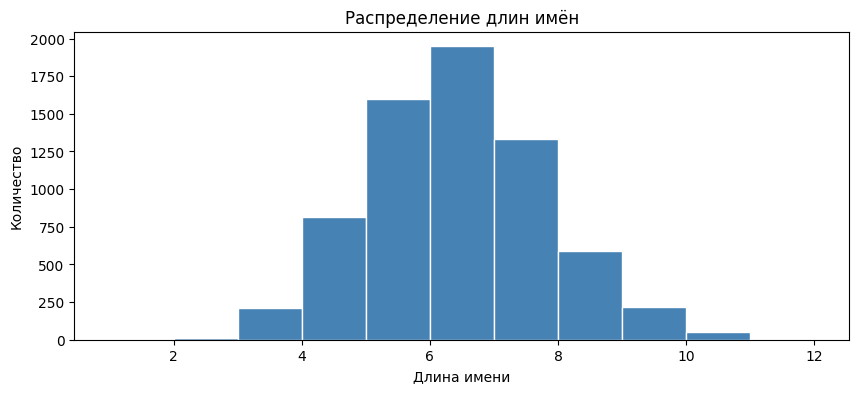

Gender
boy     3437
girl    3345
Name: count, dtype: int64
letter  count
     a   5593
     e   5038
     n   3524
     i   3264
     l   3255
     r   3070
     o   2071
     t   1745
     s   1674
     d   1532
     m   1245
     y   1243
     h   1206
     c   1063
     u    707
     b    673
     k    616
     g    526
     j    502
     v    490
     f    302
     w    271
     p    265
     z    199
     x     71
     q     61


In [2]:
df = pd.read_csv('data/babynames-clean.csv', names=['Name', 'Gender'])

lengths = df['Name'].str.len()
plt.figure(figsize=(10, 4))
plt.hist(lengths, bins=range(1, lengths.max() + 2), color='steelblue', edgecolor='white')
plt.xlabel('Длина имени')
plt.ylabel('Количество')
plt.title('Распределение длин имён')
plt.show()

print(df['Gender'].value_counts())

all_text = ''.join(df['Name'].str.lower())
letter_freq = Counter(all_text)
freq_df = pd.DataFrame(letter_freq.items(), columns=['letter', 'count']).sort_values('count', ascending=False)
print(freq_df.to_string(index=False))

### 3. Подготовка данных

In [3]:
SPECIAL = ['<SOS>', '<EOS>', '<PAD>']
alphabet = [chr(c) for c in range(ord('a'), ord('z') + 1)]
vocab = SPECIAL + alphabet

char2idx = {ch: i for i, ch in enumerate(vocab)}
idx2char = {i: ch for ch, i in char2idx.items()}

PAD_IDX = char2idx['<PAD>']
SOS_IDX = char2idx['<SOS>']
EOS_IDX = char2idx['<EOS>']

max_len = df['Name'].str.len().max() + 2

def name_to_ids(name):
    tokens = [SOS_IDX] + [char2idx[c] for c in name.lower()] + [EOS_IDX]
    tokens += [PAD_IDX] * (max_len - len(tokens))
    return tokens

df['Encoded'] = df['Name'].apply(name_to_ids)
print(df.head(3))

      Name Gender                                        Encoded
0     John    boy    [0, 12, 17, 10, 16, 1, 2, 2, 2, 2, 2, 2, 2]
1  William    boy  [0, 25, 11, 14, 14, 11, 3, 15, 1, 2, 2, 2, 2]
2    James    boy     [0, 12, 3, 15, 7, 21, 1, 2, 2, 2, 2, 2, 2]


In [4]:
df['label'] = (df['Gender'] == 'girl').astype(int)

train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df['Gender'], random_state=21)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['Gender'], random_state=21)

for d in [train_df, val_df, test_df]:
    d.reset_index(drop=True, inplace=True)

print(f'train: {len(train_df)}, val: {len(val_df)}, test: {len(test_df)}')

train: 5425, val: 678, test: 679


### 4. Рекуррентная нейронная сеть RNN

In [5]:
class NameRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, rnn_type='RNN', with_gender=False):
        super().__init__()
        self.rnn_type = rnn_type
        self.hidden_dim = hidden_dim
        self.with_gender = with_gender

        self.emb = nn.Embedding(vocab_size, embed_dim)

        if rnn_type == 'RNN':
            self.Wx = nn.Linear(embed_dim, hidden_dim)
            self.Wh = nn.Linear(hidden_dim, hidden_dim)

        elif rnn_type == 'GRU':
            self.Wxz = nn.Linear(embed_dim, hidden_dim)
            self.Whz = nn.Linear(hidden_dim, hidden_dim)
            self.Wxr = nn.Linear(embed_dim, hidden_dim)
            self.Whr = nn.Linear(hidden_dim, hidden_dim)
            self.Wxn = nn.Linear(embed_dim, hidden_dim)
            self.Whn = nn.Linear(hidden_dim, hidden_dim)

        elif rnn_type == 'LSTM':
            self.Wxi = nn.Linear(embed_dim, hidden_dim)
            self.Whi = nn.Linear(hidden_dim, hidden_dim)
            self.Wxf = nn.Linear(embed_dim, hidden_dim)
            self.Whf = nn.Linear(hidden_dim, hidden_dim)
            self.Wxg = nn.Linear(embed_dim, hidden_dim)
            self.Whg = nn.Linear(hidden_dim, hidden_dim)
            self.Wxo = nn.Linear(embed_dim, hidden_dim)
            self.Who = nn.Linear(hidden_dim, hidden_dim)
        else:
            raise ValueError(f'Unknown rnn_type: {rnn_type}')

        self.out_char = nn.Linear(hidden_dim, vocab_size)
        if with_gender:
            self.out_gender = nn.Linear(hidden_dim, 1)

    def zero_state(self, batch, device):
        h = torch.zeros(batch, self.hidden_dim, device=device)
        if self.rnn_type == 'LSTM':
            return h, torch.zeros_like(h)
        return h

    def step(self, x_emb, state):
        if self.rnn_type == 'RNN':
            h = torch.tanh(self.Wx(x_emb) + self.Wh(state))
            return h, h
        elif self.rnn_type == 'GRU':
            z = torch.sigmoid(self.Wxz(x_emb) + self.Whz(state))
            r = torch.sigmoid(self.Wxr(x_emb) + self.Whr(state))
            n = torch.tanh(self.Wxn(x_emb) + self.Whn(r * state))
            h = (1 - z) * state + z * n
            return h, h
        else:
            h, c = state
            i = torch.sigmoid(self.Wxi(x_emb) + self.Whi(h))
            f = torch.sigmoid(self.Wxf(x_emb) + self.Whf(h))
            g = torch.tanh(self.Wxg(x_emb) + self.Whg(h))
            o = torch.sigmoid(self.Wxo(x_emb) + self.Who(h))
            c_new = f * c + i * g
            h_new = o * torch.tanh(c_new)
            return h_new, (h_new, c_new)

    def forward(self, x, state=None):
        B, T = x.shape
        if state is None:
            state = self.zero_state(B, x.device)

        char_logits = []
        for t in range(T):
            emb = self.emb(x[:, t])
            h, state = self.step(emb, state)
            char_logits.append(self.out_char(h))

        logits_seq = torch.stack(char_logits, dim=1)
        last_h = h
        gender_logits = self.out_gender(last_h) if self.with_gender else None

        return logits_seq, gender_logits, state

In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

VOCAB_SIZE = len(vocab)
EMBED_DIM = 128
HIDDEN_DIM = 256
BATCH = 64

def make_seq_loaders(split_df, with_labels=False, shuffle=True):
    seqs = torch.tensor(np.array(split_df['Encoded'].tolist()), dtype=torch.long)
    if with_labels:
        labels = torch.tensor(split_df['label'].values, dtype=torch.float)
        ds = TensorDataset(seqs, labels)
    else:
        ds = TensorDataset(seqs)
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle)

train_loader_seq = make_seq_loaders(train_df)
val_loader_seq = make_seq_loaders(val_df)

device: cpu


In [7]:
def run_epoch_lm(model, loader, optimizer, criterion, training):
    model.train() if training else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for (batch,) in loader:
            batch = batch.to(device)
            logits, _, _ = model(batch)
            pred = logits[:, :-1].reshape(-1, VOCAB_SIZE)
            tgt = batch[:, 1:].reshape(-1)
            loss = criterion(pred, tgt)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item()
    return total / len(loader)


def fit_lm(model, train_loader, val_loader, epochs=100, patience=3):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    best_val = float('inf')
    wait = 0
    tr_hist, val_hist = [], []
    for ep in range(1, epochs + 1):
        tr = run_epoch_lm(model, train_loader, optimizer, criterion, True)
        val = run_epoch_lm(model, val_loader, optimizer, criterion, False)
        tr_hist.append(tr)
        val_hist.append(val)
        print(f'Epoch {ep:3d}: train={tr:.4f}  val={val:.4f}')
        if val < best_val:
            best_val = val
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print('Early stop')
                break
    return tr_hist, val_hist

In [8]:
def sample_name(model, temperature=0.8, max_len=15):
    model.eval()
    with torch.no_grad():
        x = torch.tensor([[SOS_IDX]], device=device)
        state = model.zero_state(1, device)
        result = []
        for _ in range(max_len):
            logits, _, state = model(x, state)
            probs = torch.softmax(logits[:, -1] / temperature, dim=-1)
            idx = torch.multinomial(probs, 1).item()
            ch = idx2char[idx]
            if ch == '<EOS>':
                break
            if ch not in ('<SOS>', '<PAD>'):
                result.append(ch)
            x = torch.tensor([[idx]], device=device)
        return ''.join(result)

Epoch   1: train=1.4761  val=1.3126
Epoch   2: train=1.2534  val=1.2662
Epoch   3: train=1.2158  val=1.2395
Epoch   4: train=1.1890  val=1.2203
Epoch   5: train=1.1670  val=1.2066
Epoch   6: train=1.1496  val=1.1986
Epoch   7: train=1.1352  val=1.1950
Epoch   8: train=1.1183  val=1.1862
Epoch   9: train=1.1036  val=1.1761
Epoch  10: train=1.0898  val=1.1802
Epoch  11: train=1.0780  val=1.1661
Epoch  12: train=1.0666  val=1.1636
Epoch  13: train=1.0563  val=1.1649
Epoch  14: train=1.0427  val=1.1577
Epoch  15: train=1.0340  val=1.1590
Epoch  16: train=1.0245  val=1.1591
Epoch  17: train=1.0140  val=1.1557
Epoch  18: train=1.0043  val=1.1546
Epoch  19: train=0.9947  val=1.1561
Epoch  20: train=0.9871  val=1.1528
Epoch  21: train=0.9789  val=1.1612
Epoch  22: train=0.9713  val=1.1591
Epoch  23: train=0.9626  val=1.1596
Early stop


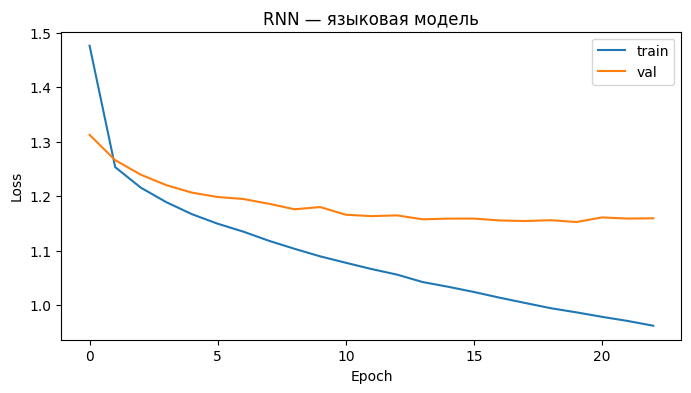

jera
zelly
hake
ralla
shannie
cheryl
antone
arnal
eliza
devon


In [9]:
def plot_losses(tr, val, title):
    plt.figure(figsize=(8, 4))
    plt.plot(tr, label='train')
    plt.plot(val, label='val')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(title)
    plt.legend()
    plt.show()

rnn_model = NameRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, rnn_type='RNN').to(device)
tr_rnn, val_rnn = fit_lm(rnn_model, train_loader_seq, val_loader_seq)
plot_losses(tr_rnn, val_rnn, 'RNN — языковая модель')

for _ in range(10):
    print(sample_name(rnn_model))

### 5. GRU

Epoch   1: train=1.5461  val=1.3262
Epoch   2: train=1.2553  val=1.2630
Epoch   3: train=1.2028  val=1.2251
Epoch   4: train=1.1681  val=1.2063
Epoch   5: train=1.1395  val=1.1885
Epoch   6: train=1.1157  val=1.1783
Epoch   7: train=1.0906  val=1.1632
Epoch   8: train=1.0685  val=1.1586
Epoch   9: train=1.0476  val=1.1528
Epoch  10: train=1.0269  val=1.1457
Epoch  11: train=1.0070  val=1.1437
Epoch  12: train=0.9911  val=1.1414
Epoch  13: train=0.9733  val=1.1442
Epoch  14: train=0.9571  val=1.1438
Epoch  15: train=0.9418  val=1.1509
Early stop


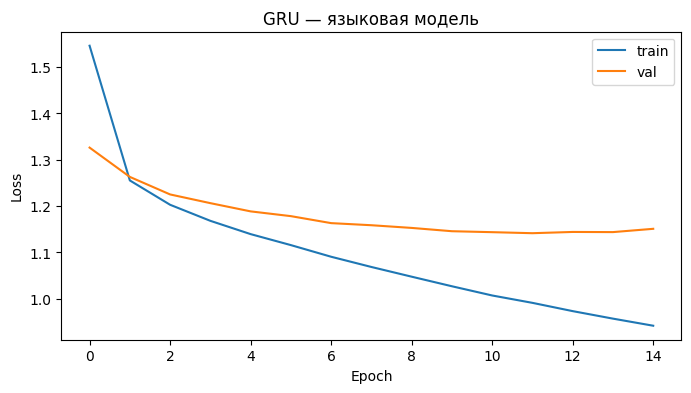

leigh
corine
shanigare
nehmad
alvis
myrte
delle
aletha
kenya
kelia


In [10]:
gru_model = NameRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, rnn_type='GRU').to(device)
tr_gru, val_gru = fit_lm(gru_model, train_loader_seq, val_loader_seq)
plot_losses(tr_gru, val_gru, 'GRU — языковая модель')

for _ in range(10):
    print(sample_name(gru_model))

### 6. LSTM

Epoch   1: train=1.6128  val=1.3475
Epoch   2: train=1.2704  val=1.2740
Epoch   3: train=1.2129  val=1.2317
Epoch   4: train=1.1761  val=1.2110
Epoch   5: train=1.1480  val=1.1895
Epoch   6: train=1.1228  val=1.1816
Epoch   7: train=1.0987  val=1.1716
Epoch   8: train=1.0759  val=1.1579
Epoch   9: train=1.0552  val=1.1520
Epoch  10: train=1.0381  val=1.1493
Epoch  11: train=1.0190  val=1.1454
Epoch  12: train=1.0032  val=1.1369
Epoch  13: train=0.9875  val=1.1352
Epoch  14: train=0.9722  val=1.1361
Epoch  15: train=0.9583  val=1.1362
Epoch  16: train=0.9453  val=1.1390
Early stop


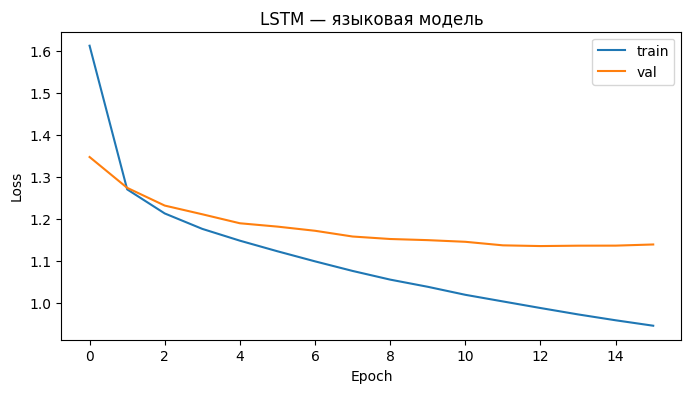

doral
ruby
valina
arly
elvera
donnie
trifah
edetta
mariah
theomaine


In [11]:
lstm_model = NameRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, rnn_type='LSTM').to(device)
tr_lstm, val_lstm = fit_lm(lstm_model, train_loader_seq, val_loader_seq)
plot_losses(tr_lstm, val_lstm, 'LSTM — языковая модель')

for _ in range(10):
    print(sample_name(lstm_model))

### 7. Сравнение моделей

**7a. Своя метрика — доля имён без спецтокенов.** Можно измерить, насколько часто модель генерирует «чистые» имена (без служебных символов и с длиной от 3 до 12). Это косвенно отражает качество распределения по словарю.

Стандартная метрика — **перплексия**:

$$P = \exp\left(-\frac{1}{N}\sum_{i=1}^N \log p(w_i)\right) = \exp(CE)$$

Чем меньше перплексия, тем увереннее модель. Для равномерного распределения перплексия = размеру словаря V.

**7e.** При |vocab| = 29 перплексия случайной модели: $\exp(\log 29) = 29$.

In [12]:
def compute_perplexity(model, loader):
    model.eval()
    ce = nn.CrossEntropyLoss()
    total_loss, total_tokens = 0.0, 0
    with torch.no_grad():
        for (batch,) in loader:
            batch = batch.to(device)
            logits, _, _ = model(batch)
            pred = logits[:, :-1].reshape(-1, VOCAB_SIZE)
            tgt = batch[:, 1:].reshape(-1)
            total_loss += ce(pred, tgt).item() * tgt.size(0)
            total_tokens += tgt.size(0)
    return np.exp(total_loss / total_tokens)

In [13]:
all_ids = torch.tensor(np.array(df['Encoded'].tolist()), dtype=torch.long)
flat = all_ids.flatten().tolist()
freq = Counter(flat)
freq_vec = torch.zeros(VOCAB_SIZE)
for k, v in freq.items():
    freq_vec[k] = v
freq_vec /= freq_vec.sum()

N, L = all_ids.shape
probs_uniform = torch.ones(N, L, VOCAB_SIZE) / VOCAB_SIZE
probs_freq = freq_vec.unsqueeze(0).unsqueeze(0).expand(N, L, -1)

def perp_from_probs(probs, targets):
    p = probs.gather(2, targets.unsqueeze(-1)).squeeze(-1)
    return torch.exp(-torch.log(p).mean()).item()

print('Перплексия равномерной модели:', perp_from_probs(probs_uniform, all_ids))
print('Перплексия частотной модели:  ', perp_from_probs(probs_freq, all_ids))

print(f'RNN  perplexity: {compute_perplexity(rnn_model, val_loader_seq):.2f}')
print(f'GRU  perplexity: {compute_perplexity(gru_model, val_loader_seq):.2f}')
print(f'LSTM perplexity: {compute_perplexity(lstm_model, val_loader_seq):.2f}')

Перплексия равномерной модели: 28.999956130981445
Перплексия частотной модели:   11.156719207763672


RNN  perplexity: 3.19
GRU  perplexity: 3.17
LSTM perplexity: 3.13


### 8. Гендерная классификация

**BCE vs NLL.** Задача бинарная — один выход. `BCEWithLogitsLoss` работает напрямую с логитом и численно устойчива (сигмоида и логарифм объединены). `NLLLoss` требует двух нейронов и применения `LogSoftmax` — избыточно для бинарного случая. Поэтому используем BCE.

In [14]:
train_loader_cls = make_seq_loaders(train_df, with_labels=True)
val_loader_cls = make_seq_loaders(val_df, with_labels=True)
test_loader_cls = make_seq_loaders(test_df, with_labels=True, shuffle=False)


def run_epoch_cls(model, loader, optimizer, criterion, training):
    model.train() if training else model.eval()
    total = 0.0
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for seqs, labels in loader:
            seqs, labels = seqs.to(device), labels.to(device)
            _, g_logits, _ = model(seqs)
            loss = criterion(g_logits.squeeze(), labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item()
    return total / len(loader)


def fit_cls(model, train_loader, val_loader, epochs=100, patience=10):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    best_val = float('inf')
    wait = 0
    tr_hist, val_hist = [], []
    for ep in range(1, epochs + 1):
        tr = run_epoch_cls(model, train_loader, optimizer, criterion, True)
        val = run_epoch_cls(model, val_loader, optimizer, criterion, False)
        tr_hist.append(tr)
        val_hist.append(val)
        print(f'Epoch {ep:3d}: train={tr:.4f}  val={val:.4f}')
        if val < best_val:
            best_val = val
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print('Early stop')
                break
    return tr_hist, val_hist


def eval_cls(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for seqs, labels in loader:
            seqs = seqs.to(device)
            _, g_logits, _ = model(seqs)
            probs = torch.sigmoid(g_logits.squeeze()).cpu().numpy()
            all_preds.extend(probs.tolist())
            all_labels.extend(labels.numpy().tolist())
    return roc_auc_score(all_labels, all_preds)

Epoch   1: train=0.6682  val=0.5172
Epoch   2: train=0.4834  val=0.4208
Epoch   3: train=0.4389  val=0.4012
Epoch   4: train=0.4172  val=0.3931
Epoch   5: train=0.3907  val=0.3752
Epoch   6: train=0.3752  val=0.3652
Epoch   7: train=0.3666  val=0.3879
Epoch   8: train=0.3416  val=0.3638
Epoch   9: train=0.3312  val=0.3677
Epoch  10: train=0.3095  val=0.3794
Epoch  11: train=0.3004  val=0.3531
Epoch  12: train=0.2876  val=0.3879
Epoch  13: train=0.2695  val=0.4179
Epoch  14: train=0.2485  val=0.3863
Epoch  15: train=0.2495  val=0.3943
Epoch  16: train=0.2289  val=0.3885
Epoch  17: train=0.2101  val=0.4402
Epoch  18: train=0.1950  val=0.4174
Epoch  19: train=0.1971  val=0.4236
Epoch  20: train=0.1794  val=0.4529
Epoch  21: train=0.1659  val=0.4527
Early stop


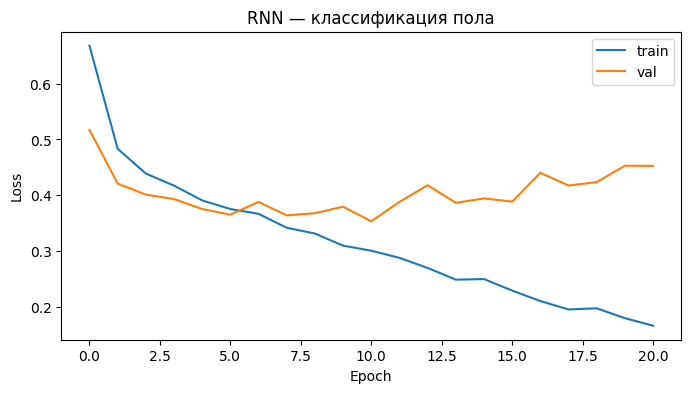

ROC AUC (RNN): 0.8960690732384589


In [15]:
rnn_cls = NameRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, rnn_type='RNN', with_gender=True).to(device)
tr, val = fit_cls(rnn_cls, train_loader_cls, val_loader_cls)
plot_losses(tr, val, 'RNN — классификация пола')
print('ROC AUC (RNN):', eval_cls(rnn_cls, test_loader_cls))

Epoch   1: train=0.5273  val=0.4082
Epoch   2: train=0.4153  val=0.3665
Epoch   3: train=0.3770  val=0.3631
Epoch   4: train=0.3408  val=0.3506
Epoch   5: train=0.3106  val=0.3539
Epoch   6: train=0.2752  val=0.3703
Epoch   7: train=0.2397  val=0.3922
Epoch   8: train=0.1938  val=0.3712
Epoch   9: train=0.1697  val=0.3942
Epoch  10: train=0.1407  val=0.4752
Epoch  11: train=0.1101  val=0.5241
Epoch  12: train=0.0928  val=0.5634
Epoch  13: train=0.0760  val=0.5953
Epoch  14: train=0.0675  val=0.6050
Early stop


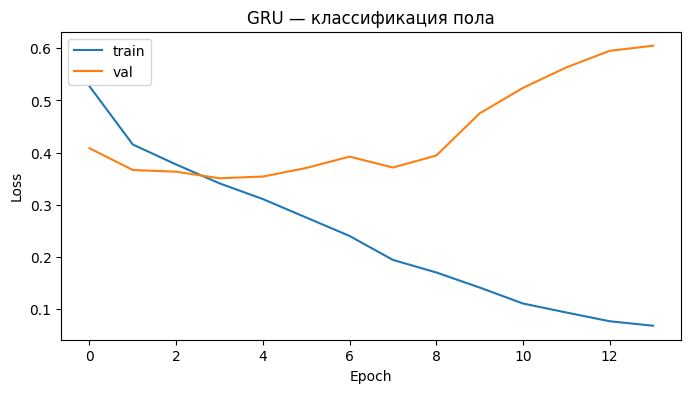

ROC AUC (GRU): 0.9046424852481778


In [16]:
gru_cls = NameRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, rnn_type='GRU', with_gender=True).to(device)
tr, val = fit_cls(gru_cls, train_loader_cls, val_loader_cls)
plot_losses(tr, val, 'GRU — классификация пола')
print('ROC AUC (GRU):', eval_cls(gru_cls, test_loader_cls))

Epoch   1: train=0.5514  val=0.3925
Epoch   2: train=0.4249  val=0.3719
Epoch   3: train=0.3912  val=0.3951
Epoch   4: train=0.3615  val=0.3759
Epoch   5: train=0.3353  val=0.3681
Epoch   6: train=0.3058  val=0.3784
Epoch   7: train=0.2838  val=0.3994
Epoch   8: train=0.2521  val=0.3760
Epoch   9: train=0.2174  val=0.4037
Epoch  10: train=0.1916  val=0.4416
Epoch  11: train=0.1604  val=0.4825
Epoch  12: train=0.1322  val=0.5396
Epoch  13: train=0.1203  val=0.5213
Epoch  14: train=0.0974  val=0.5639
Epoch  15: train=0.0822  val=0.5086
Early stop


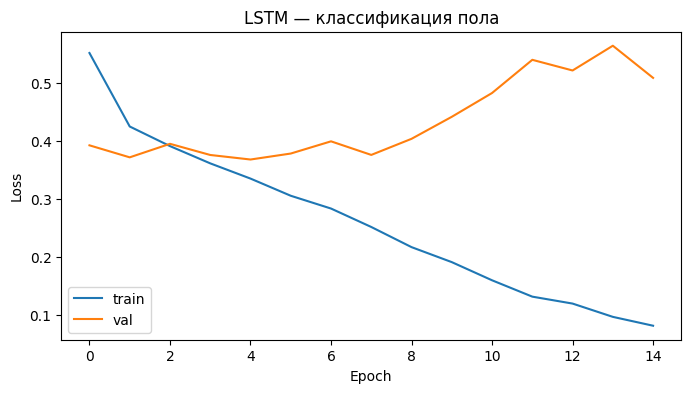

ROC AUC (LSTM): 0.9126518569940992


In [17]:
lstm_cls = NameRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, rnn_type='LSTM', with_gender=True).to(device)
tr, val = fit_cls(lstm_cls, train_loader_cls, val_loader_cls)
plot_losses(tr, val, 'LSTM — классификация пола')
print('ROC AUC (LSTM):', eval_cls(lstm_cls, test_loader_cls))

### 9. Исчезающий градиент

In [18]:
modal_len = train_df['Name'].str.len().mode()[0]
fixed_train = train_df[train_df['Name'].str.len() == modal_len].reset_index(drop=True)
fixed_val = val_df[val_df['Name'].str.len() == modal_len].reset_index(drop=True)

x_sample = torch.tensor([fixed_train.loc[0, 'Encoded']], dtype=torch.long)
y_sample = torch.tensor([fixed_train.loc[0, 'label']], dtype=torch.float)

In [19]:
def get_grad_norms(model, x, y, lm_mode=False):
    grads = []

    def hook(module, grad_in, grad_out):
        grads.append(grad_out[0].detach().cpu())

    handle = model.emb.register_full_backward_hook(hook)
    model.train()
    x, y = x.to(device), y.to(device)

    if lm_mode:
        logits, _, _ = model(x)
        pred = logits[:, :-1].reshape(-1, VOCAB_SIZE)
        tgt = x[:, 1:].reshape(-1)
        loss = nn.CrossEntropyLoss()(pred, tgt)
    else:
        _, g_logits, _ = model(x)
        loss = nn.BCEWithLogitsLoss()(g_logits.squeeze(-1), y)

    model.zero_grad()
    loss.backward()
    handle.remove()

    grad_stack = torch.stack(grads).squeeze(1)
    norms = grad_stack.view(len(grads), -1).norm(dim=1)
    return norms


def plot_grad_norms(norms, title):
    plt.figure(figsize=(8, 4))
    plt.plot(norms.numpy(), marker='o')
    plt.xlabel('Позиция токена')
    plt.ylabel('Норма градиента')
    plt.title(title)
    plt.grid(True)
    plt.show()

/tmp/ipykernel_283236/2184546566.py:21: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


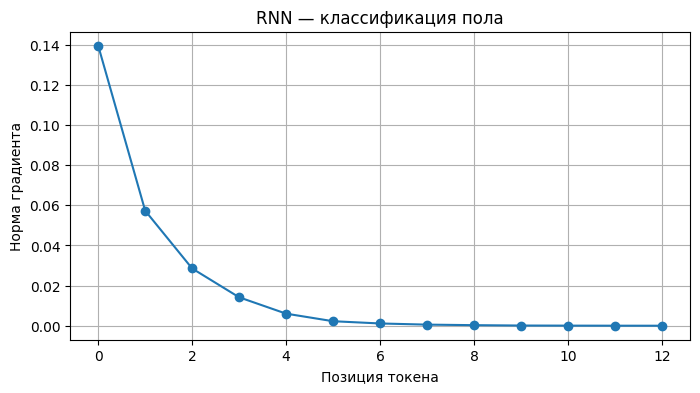

RNN norms: tensor([1.3944e-01, 5.7284e-02, 2.8516e-02, 1.4173e-02, 6.0261e-03, 2.2553e-03,
        1.1351e-03, 5.5806e-04, 2.9206e-04, 1.0938e-04, 5.7553e-05, 2.6574e-05,
        1.2855e-05])


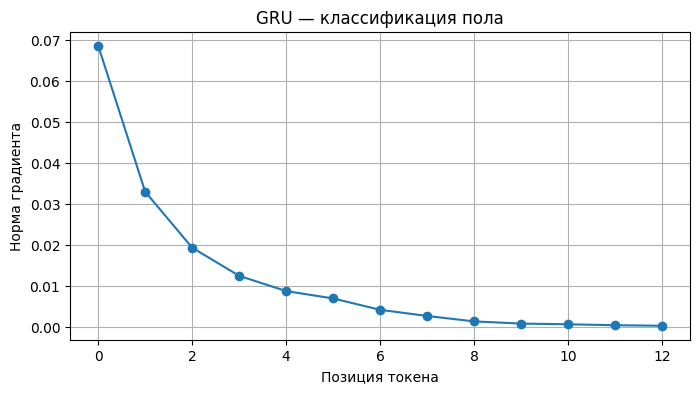

GRU norms: tensor([0.0686, 0.0330, 0.0193, 0.0124, 0.0087, 0.0069, 0.0041, 0.0026, 0.0013,
        0.0008, 0.0006, 0.0004, 0.0003])


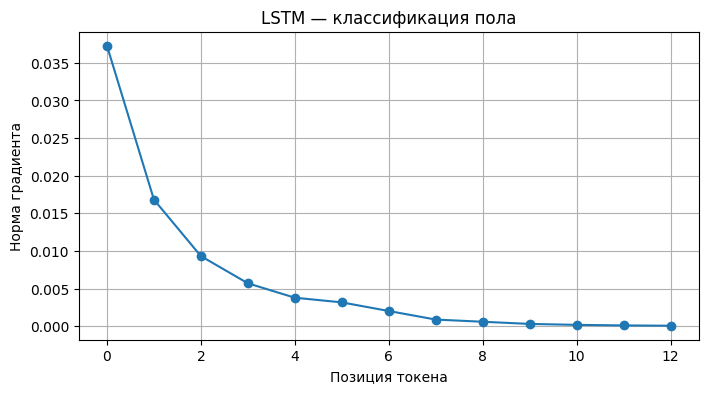

LSTM norms: tensor([3.7279e-02, 1.6819e-02, 9.3137e-03, 5.6991e-03, 3.7829e-03, 3.1637e-03,
        2.0160e-03, 8.7740e-04, 5.8750e-04, 2.9887e-04, 1.7354e-04, 1.0030e-04,
        6.0016e-05])


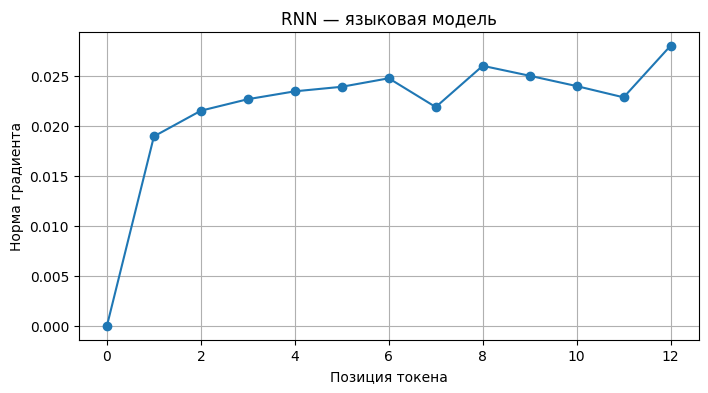

RNN norms: tensor([0.0000, 0.0189, 0.0215, 0.0226, 0.0234, 0.0239, 0.0247, 0.0219, 0.0260,
        0.0250, 0.0240, 0.0228, 0.0280])


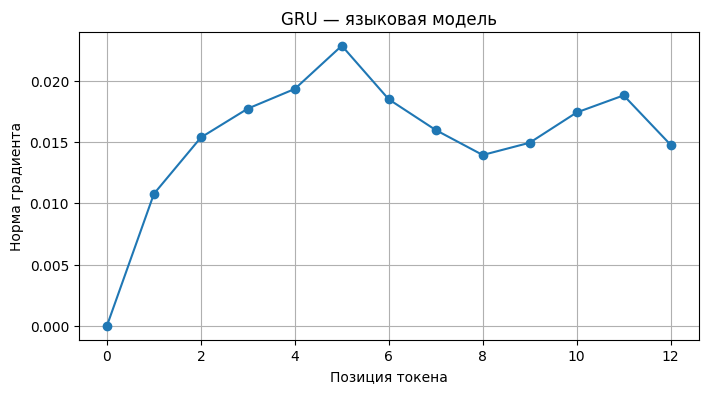

GRU norms: tensor([0.0000, 0.0108, 0.0154, 0.0178, 0.0194, 0.0229, 0.0185, 0.0160, 0.0140,
        0.0150, 0.0174, 0.0188, 0.0148])


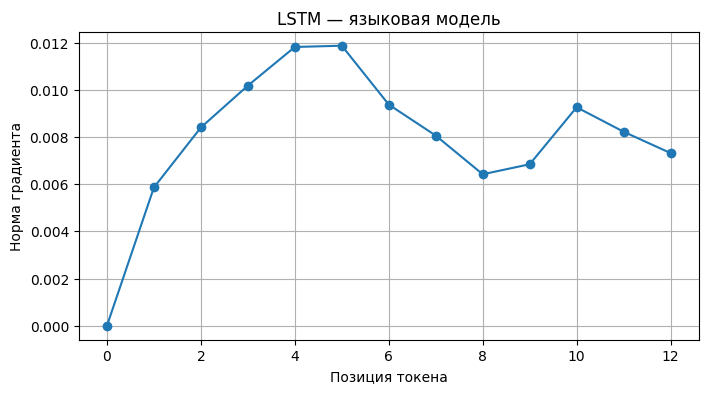

LSTM norms: tensor([0.0000, 0.0059, 0.0084, 0.0102, 0.0118, 0.0119, 0.0094, 0.0081, 0.0064,
        0.0068, 0.0093, 0.0082, 0.0073])


In [20]:
for arch in ['RNN', 'GRU', 'LSTM']:
    m = NameRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, rnn_type=arch, with_gender=True).to(device)
    norms = get_grad_norms(m, x_sample, y_sample, lm_mode=False)
    plot_grad_norms(norms, f'{arch} — классификация пола')
    print(f'{arch} norms:', norms)

for arch in ['RNN', 'GRU', 'LSTM']:
    m = NameRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, rnn_type=arch, with_gender=False).to(device)
    norms = get_grad_norms(m, x_sample, y_sample, lm_mode=True)
    plot_grad_norms(norms, f'{arch} — языковая модель')
    print(f'{arch} norms:', norms)

**9g. Разница между задачами.** В языковой модели градиент поступает с каждого шага — каждая позиция получает собственный сигнал ошибки. При классификации пола ошибка считается только по последнему скрытому состоянию и затухает при обратном распространении. У RNN это затухание сильное, у GRU и LSTM — значительно меньше благодаря механизму ворот.

**9h. Зачем фиксированная длина.** Нормы градиентов по позициям сравнимы только при одинаковой длине. Если имена разной длины, одна и та же позиция находится на разном расстоянии от выхода, и усреднение теряет смысл.

### 10. Многозадачное обучение

In [21]:
def run_epoch_multitask(model, loader, optimizer, crit_cls, crit_lm, training):
    model.train() if training else model.eval()
    total_cls, total_lm = 0.0, 0.0
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for seqs, labels in loader:
            seqs, labels = seqs.to(device), labels.to(device)
            logits_seq, g_logits, _ = model(seqs)

            loss_cls = crit_cls(g_logits.squeeze(), labels)
            pred_lm = logits_seq[:, :-1].reshape(-1, VOCAB_SIZE)
            tgt_lm = seqs[:, 1:].reshape(-1)
            loss_lm = crit_lm(pred_lm, tgt_lm)

            loss = loss_cls + loss_lm
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_cls += loss_cls.item()
            total_lm += loss_lm.item()
    n = len(loader)
    return total_cls / n, total_lm / n


def fit_multitask(model, train_loader, val_loader, epochs=100, patience=5):
    crit_cls = nn.BCEWithLogitsLoss()
    crit_lm = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    best = float('inf')
    wait = 0
    for ep in range(1, epochs + 1):
        tr_c, tr_l = run_epoch_multitask(model, train_loader, optimizer, crit_cls, crit_lm, True)
        va_c, va_l = run_epoch_multitask(model, val_loader, optimizer, crit_cls, crit_lm, False)
        combined = va_c + va_l
        print(f'Epoch {ep:3d}: cls {tr_c:.4f}/{va_c:.4f}  lm {tr_l:.4f}/{va_l:.4f}')
        if combined < best:
            best = combined
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print('Early stop')
                break

lstm_mt = NameRNN(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, rnn_type='LSTM', with_gender=True).to(device)
fit_multitask(lstm_mt, train_loader_cls, val_loader_cls)
print('ROC AUC (LSTM multitask):', eval_cls(lstm_mt, test_loader_cls))

Epoch   1: cls 0.6111/0.4714  lm 1.6357/1.3775
Epoch   2: cls 0.4529/0.3926  lm 1.2958/1.2900
Epoch   3: cls 0.4051/0.3772  lm 1.2426/1.2606
Epoch   4: cls 0.3702/0.4140  lm 1.2091/1.2392


Epoch   5: cls 0.3484/0.4135  lm 1.1858/1.2210
Epoch   6: cls 0.3328/0.3595  lm 1.1644/1.2028
Epoch   7: cls 0.2948/0.3724  lm 1.1466/1.1936
Epoch   8: cls 0.2708/0.3786  lm 1.1321/1.1876
Epoch   9: cls 0.2405/0.3876  lm 1.1192/1.1783
Epoch  10: cls 0.2195/0.4006  lm 1.1063/1.1771
Epoch  11: cls 0.1926/0.4600  lm 1.0953/1.1689
Early stop
ROC AUC (LSTM multitask): 0.9271867407150296


### 11. Визуализация эмбеддингов

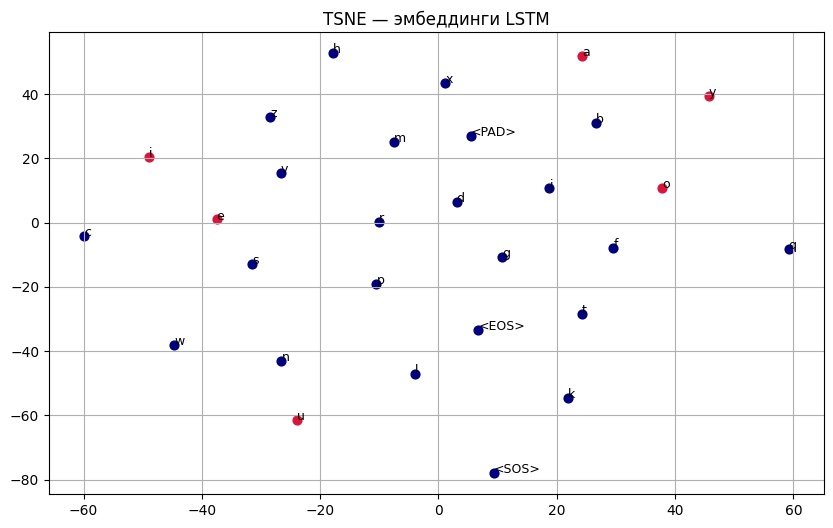

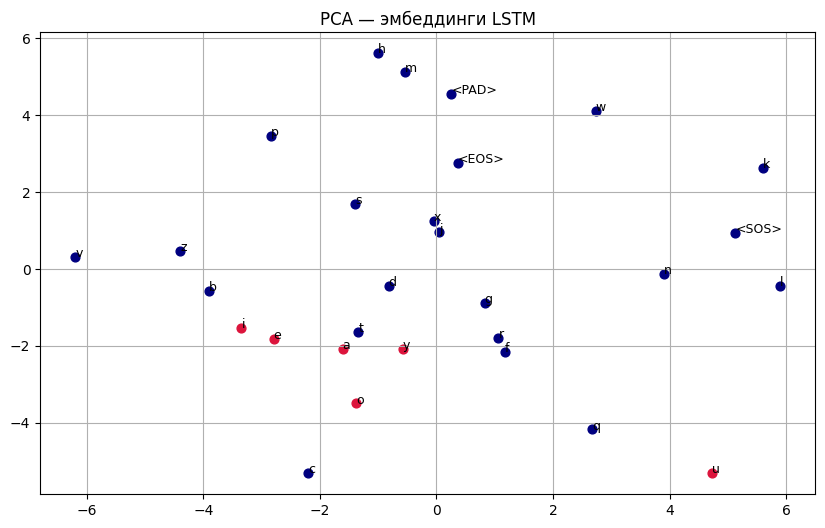

In [22]:
emb_weights = lstm_model.emb.weight.detach().cpu().numpy()

tsne_coords = TSNE(n_components=2, perplexity=15, random_state=42).fit_transform(emb_weights)
pca_coords = PCA(n_components=2).fit_transform(emb_weights)

vowels = set('aeiouy')

def plot_emb(coords, title):
    plt.figure(figsize=(10, 6))
    for i, ch in enumerate(vocab):
        color = 'crimson' if ch in vowels else 'navy'
        plt.scatter(*coords[i], color=color, s=40)
        plt.annotate(ch, coords[i], fontsize=9)
    plt.title(title)
    plt.grid(True)
    plt.show()

plot_emb(tsne_coords, 'TSNE — эмбеддинги LSTM')
plot_emb(pca_coords, 'PCA — эмбеддинги LSTM')

**11f. Выводы.** Гласные (a, e, i, o, u, y) образуют отдельный кластер — модель обнаружила фонетическое различие из данных. Спецтокены (`<SOS>`, `<EOS>`, `<PAD>`) располагаются особняком, так как встречаются только в граничных позициях. PCA показывает глобальную структуру, TSNE выделяет локальные группы схожих по контексту букв.

### 12. Сохранение модели

In [23]:
checkpoint = {
    'state_dict': lstm_mt.state_dict(),
    'vocab_size': VOCAB_SIZE,
    'embed_dim': EMBED_DIM,
    'hidden_dim': HIDDEN_DIM,
    'rnn_type': 'LSTM',
}

with open('data/multitask_model.pkl', 'wb') as f:
    pickle.dump(checkpoint, f)

print('Модель сохранена.')

Модель сохранена.


In [24]:
with open('data/multitask_model.pkl', 'rb') as f:
    ckpt = pickle.load(f)

restored = NameRNN(
    ckpt['vocab_size'], ckpt['embed_dim'], ckpt['hidden_dim'],
    rnn_type=ckpt['rnn_type'], with_gender=True
).to(device)
restored.load_state_dict(ckpt['state_dict'])
restored.eval()

auc = eval_cls(restored, test_loader_cls)
print(f'ROC AUC после загрузки: {auc:.4f}')

preds_all, labels_all = [], []
with torch.no_grad():
    for seqs, labels in test_loader_cls:
        seqs = seqs.to(device)
        _, g_logits, _ = restored(seqs)
        probs = torch.sigmoid(g_logits.squeeze()).cpu().numpy()
        preds_all.extend(probs.tolist())
        labels_all.extend(labels.numpy().tolist())

pd.DataFrame({'predicted_gender': preds_all}).to_csv('data/test_predictions.csv', index=False)
print('Предсказания сохранены.')

ROC AUC после загрузки: 0.9272
Предсказания сохранены.
